# 02. Linear / probabilistic models: Logistic Regression and Gaussian Naive Bayes
**Run on:** Laptop A · **Approx. runtime:** ~3 min on a 4-core laptop


**Protocol (same for every model):**
- Each row is one *(GPS point, candidate arc)* pair. The label is 1 if the arc is the point's reference arc.
- **5-fold GroupKFold by trip** on the 78 usable training trips. Each fold fits on a 300k-row sample of points (KNN uses 100k) and is scored on all candidates of the held-out trips.
- The model is then **refit on the training split** and scored on the **10 student-test trips**.
- **Metrics:**
  - macro F1 / precision / recall: candidate level, threshold 0.5
  - log loss
  - **Top-1 accuracy**: the share of GPS points whose highest-scoring candidate is the reference arc
  - continuity
- The **HMM/Viterbi** decoder (parameters in `artifacts/hmm_params.json`) is then run on this model's probabilities to compare *classifier only* with *classifier + HMM*.


**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## Logistic Regression


**What it does:** learns one weight per (standardised) feature, sums them, and passes the total through a sigmoid to get P(reference arc).
- **Why it suits PathSnap:** fast, interpretable (the sign and size of each weight), and gives probabilities the HMM can use.
- **Limitation:** one linear decision boundary, so it can't express interactions like *close AND same direction* unless they're engineered.
- **Hyperparameters:** C = 1.0 (inverse L2 regularisation), lbfgs, max_iter 2000.
- **Loss:** regularised binary cross-entropy (log loss).

In [3]:
make_logreg = lambda: make_model("logreg", SEED)
print(make_logreg())
cv_logreg = nb.run_cv(make_logreg, tr, tr_pts, max_rows=300000)
cv_logreg.round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=2000))])


  fold 0: F1=0.8940 top1=0.8550 ll=0.1817


  fold 1: F1=0.9069 top1=0.8749 ll=0.1446


  fold 2: F1=0.8966 top1=0.8622 ll=0.1851


  fold 3: F1=0.9352 top1=0.9173 ll=0.1154


  fold 4: F1=0.8884 top1=0.8422 ll=0.1659


CV time 6s | mean macro F1 0.9042 ± 0.0186


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.8940,0.8305,0.8228,0.1817,0.8550,0.0530,0.0014,0.7532
1,0.9069,0.8651,0.8182,0.1446,0.8749,0.0480,0.0015,0.7672
2,0.8966,0.8527,0.8192,0.1851,0.8622,0.0389,0.0009,0.5816
3,0.9352,0.9001,0.8843,0.1154,0.9173,0.0197,0.0006,0.6862
4,0.8884,0.8290,0.7969,0.1659,0.8422,0.0193,0.0006,0.5723


In [4]:
model_logreg, train_logreg, test_logreg, p_logreg = nb.fit_and_evaluate(make_logreg, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_logreg['continuity']:.4f} | inference {test_logreg['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("Logistic Regression", cv_logreg, train_logreg, test_logreg)

fit 0.7s on 300,108 rows
student-test continuity (classifier only): 0.9188 | inference 0.0005 ms/point


Logistic Regression,train (fit sample),CV mean (5 folds),student test
macro F1,0.9036,0.9042,0.9034
precision,0.8515,0.8555,0.8372
recall,0.8299,0.8283,0.8416
log loss,0.1579,0.1585,0.1510
Top-1 accuracy,0.8698,0.8703,0.8621


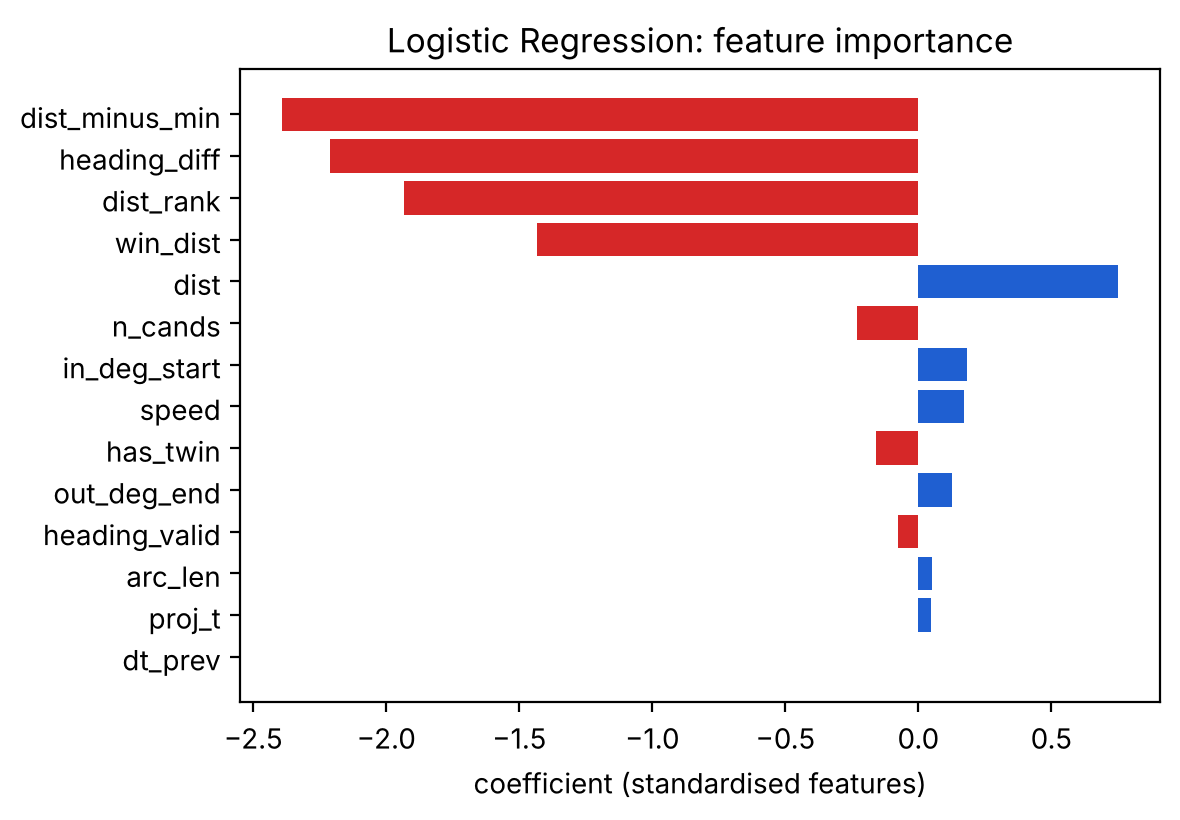

In [5]:
imp_logreg = nb.plot_importance(model_logreg, te, "Logistic Regression")

Logistic Regression: mean over 10 trips
cls_top1          0.8763
hmm_top1          0.9253
cls_route_f1      0.7526
hmm_route_f1      0.9538
cls_continuity    0.9188
hmm_continuity    0.9766


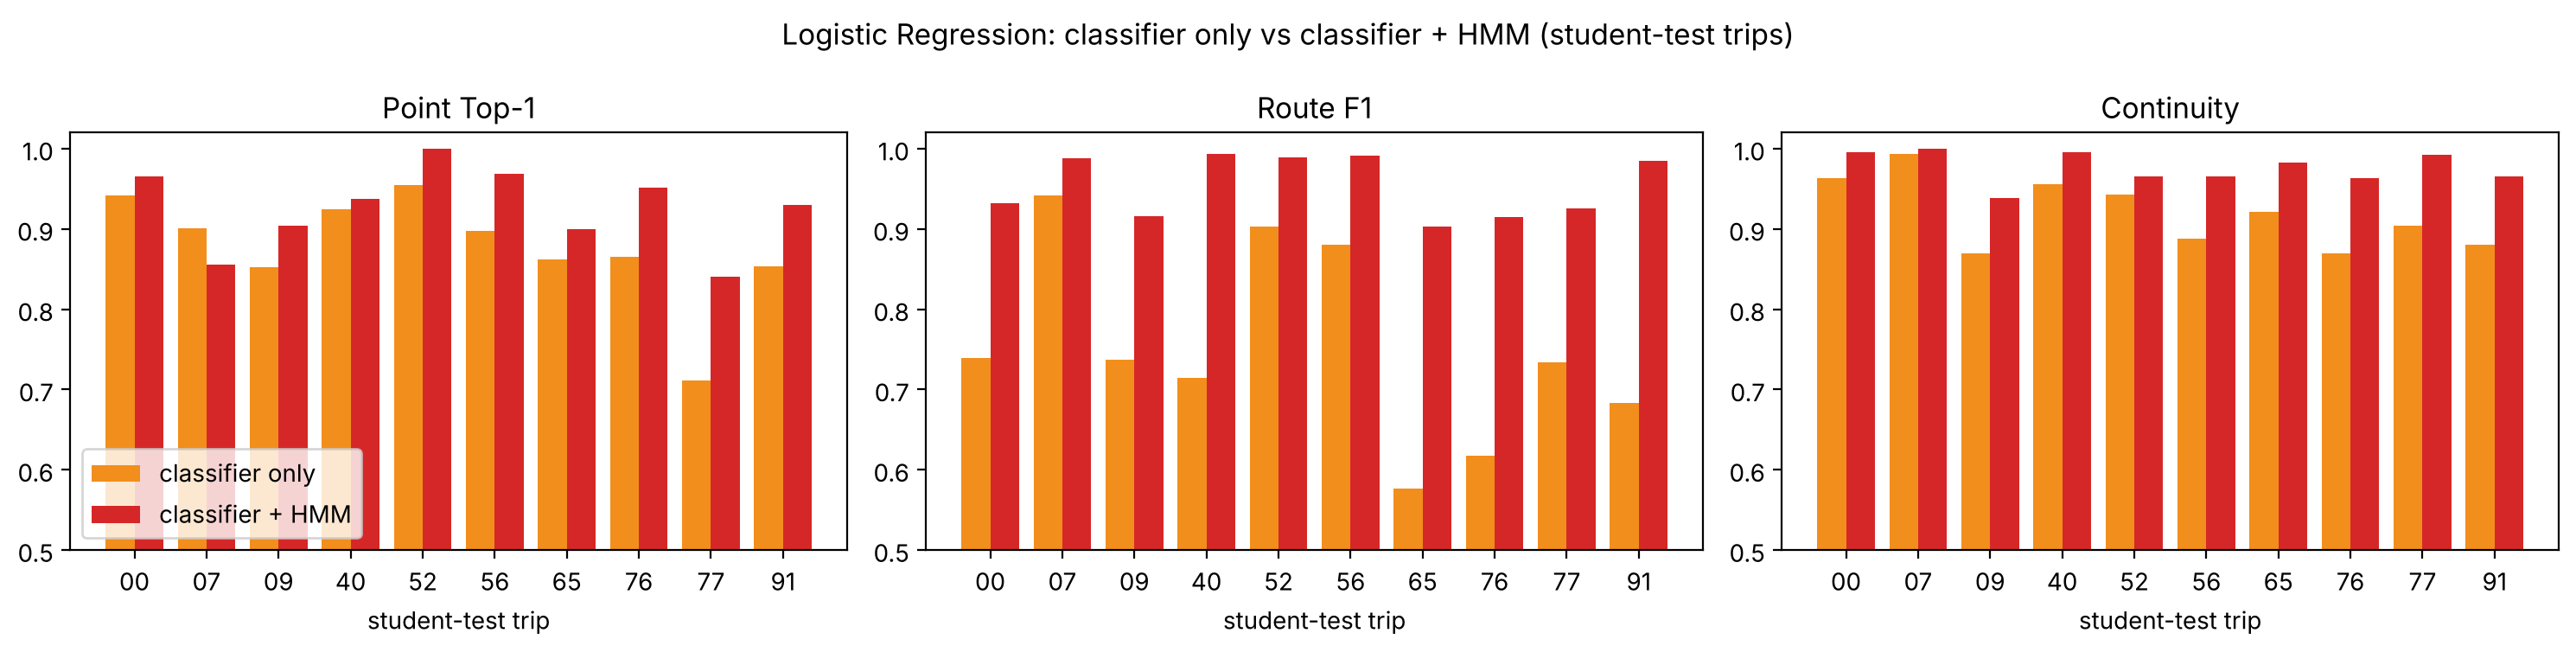

saved results/notebooks/logreg.json


In [6]:
hmm_logreg = nb.hmm_compare(model_logreg, te, "Logistic Regression")
nb.plot_hmm(hmm_logreg, "Logistic Regression: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("logreg", cv_logreg, train_logreg, test_logreg,
                {"hmm_mean": hmm_logreg.drop(columns=["trip", "model"]).mean().to_dict()})

## Gaussian Naive Bayes


**What it does:** fits a Gaussian per feature for each class and combines them with Bayes' rule, **assuming features are independent given the class**.
- **Why tried:** a very fast probabilistic baseline.
- **Limitation:** our features are strongly correlated (dist, dist_rank, dist_minus_min, win_dist all measure closeness). It double-counts that evidence and becomes over-confident, which shows up as poor log loss.
- **Hyperparameters:** var_smoothing = 1e-9.
- **Objective:** maximum likelihood of the class-conditional Gaussians.

In [7]:
make_gnb = lambda: make_model("gnb", SEED)
print(make_gnb())
cv_gnb = nb.run_cv(make_gnb, tr, tr_pts, max_rows=300000)
cv_gnb.round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('gaussiannb', GaussianNB())])


  fold 0: F1=0.8282 top1=0.8412 ll=0.5012


  fold 1: F1=0.8423 top1=0.8567 ll=0.3636


  fold 2: F1=0.8087 top1=0.8483 ll=0.8054


  fold 3: F1=0.8583 top1=0.9026 ll=0.3038


  fold 4: F1=0.8526 top1=0.8271 ll=0.3518


CV time 3s | mean macro F1 0.8380 ± 0.0200


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.8282,0.6320,0.8668,0.5012,0.8412,0.0558,0.0015,0.1349
1,0.8423,0.6376,0.8845,0.3636,0.8567,0.0463,0.0015,0.1287
2,0.8087,0.5973,0.8983,0.8054,0.8483,0.0441,0.0010,0.1217
3,0.8583,0.6623,0.9318,0.3038,0.9026,0.0488,0.0014,0.1254
4,0.8526,0.6770,0.8670,0.3518,0.8271,0.0464,0.0014,0.1282


In [8]:
model_gnb, train_gnb, test_gnb, p_gnb = nb.fit_and_evaluate(make_gnb, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_gnb['continuity']:.4f} | inference {test_gnb['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("Gaussian Naive Bayes", cv_gnb, train_gnb, test_gnb)

fit 0.1s on 300,108 rows
student-test continuity (classifier only): 0.9034 | inference 0.0014 ms/point


Gaussian Naive Bayes,train (fit sample),CV mean (5 folds),student test
macro F1,0.8352,0.8380,0.8250
precision,0.6318,0.6412,0.6067
recall,0.8928,0.8897,0.8931
log loss,0.4566,0.4652,0.5074
Top-1 accuracy,0.8542,0.8552,0.8490


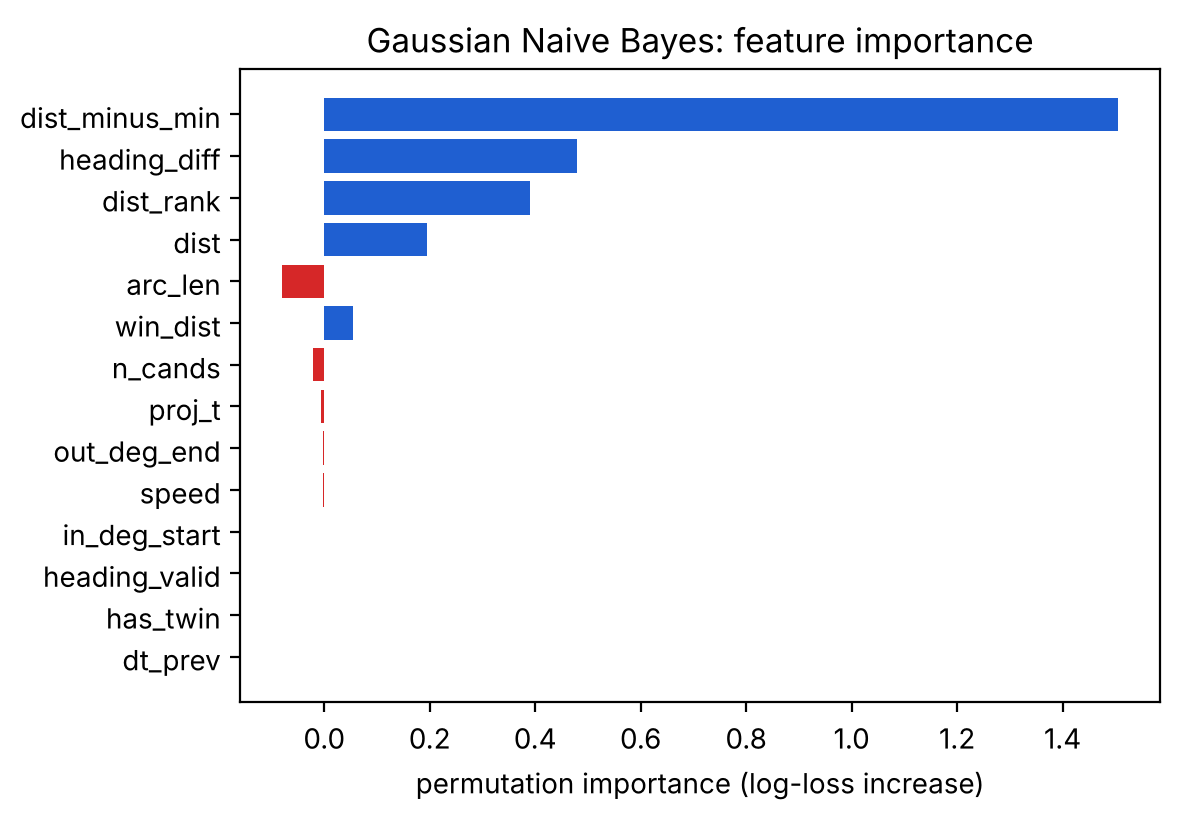

In [9]:
imp_gnb = nb.plot_importance(model_gnb, te, "Gaussian Naive Bayes")

Gaussian Naive Bayes: mean over 10 trips
cls_top1          0.8607
hmm_top1          0.9096
cls_route_f1      0.7091
hmm_route_f1      0.9263
cls_continuity    0.9034
hmm_continuity    0.9730


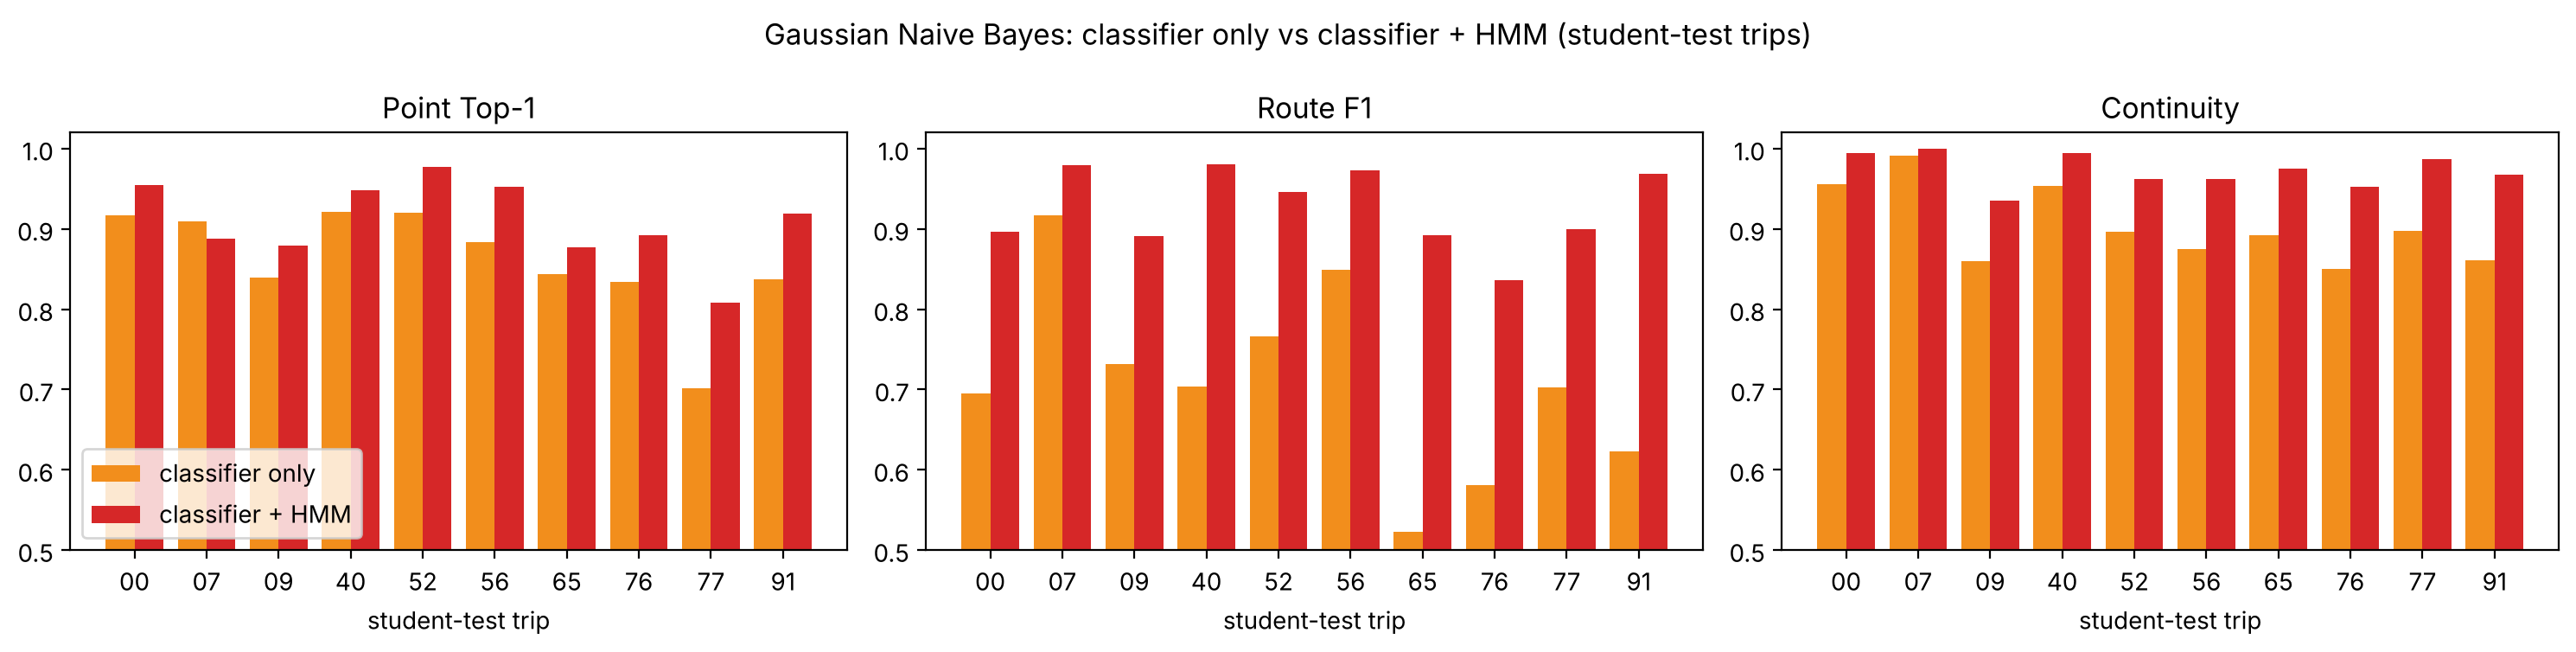

saved results/notebooks/gnb.json


In [10]:
hmm_gnb = nb.hmm_compare(model_gnb, te, "Gaussian Naive Bayes")
nb.plot_hmm(hmm_gnb, "Gaussian Naive Bayes: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("gnb", cv_gnb, train_gnb, test_gnb,
                {"hmm_mean": hmm_gnb.drop(columns=["trip", "model"]).mean().to_dict()})

## Comparison of the models in this notebook

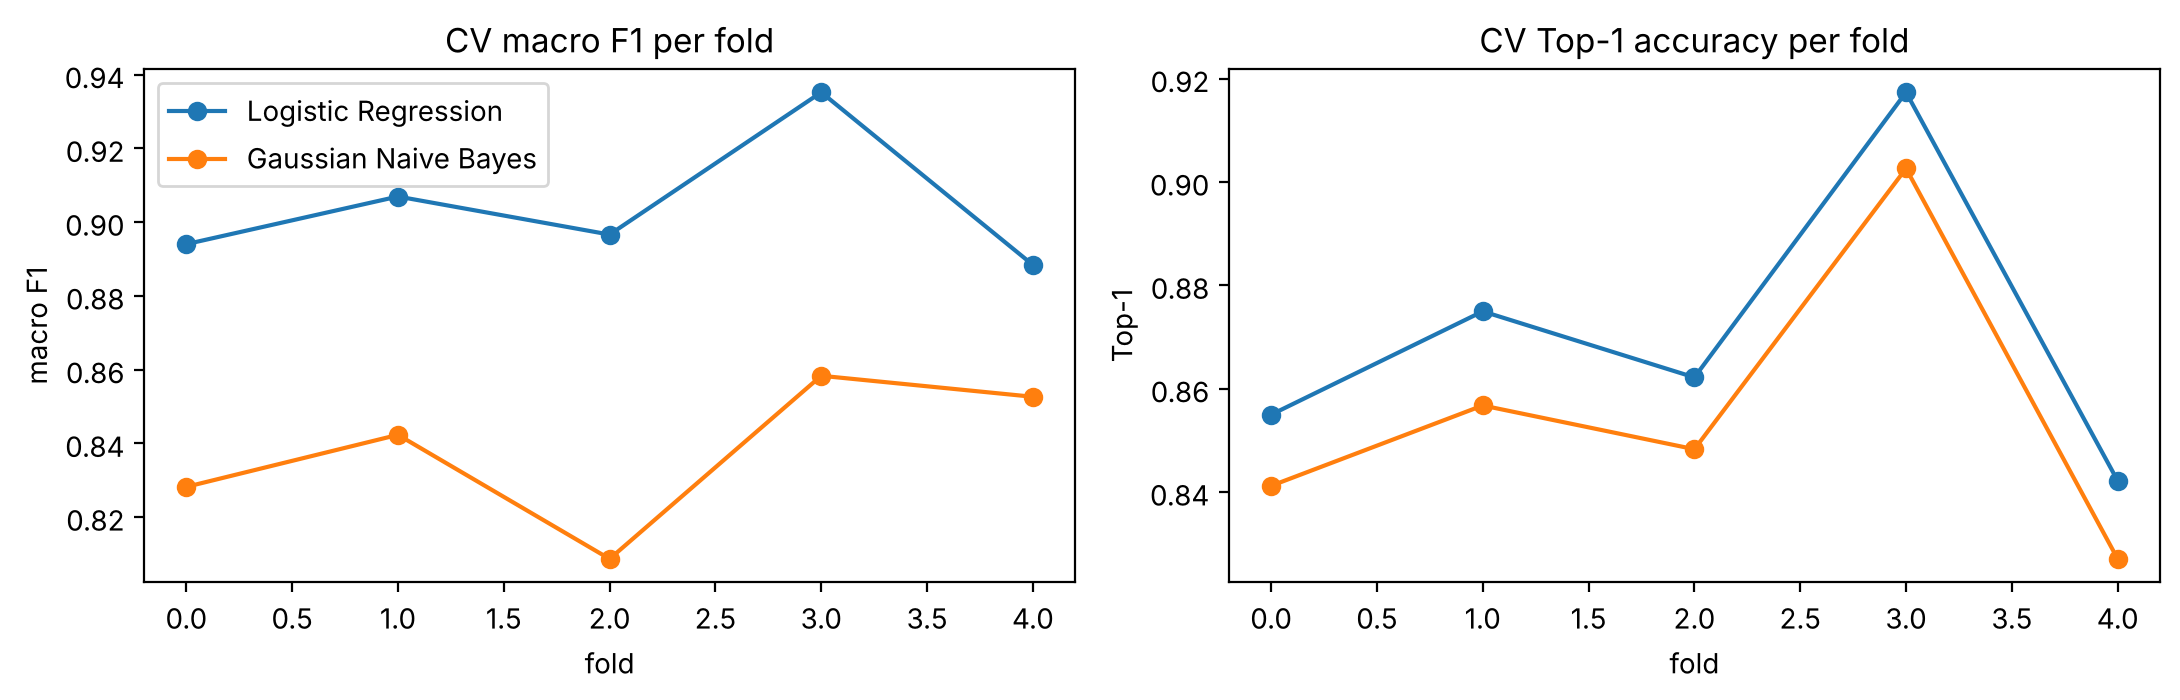

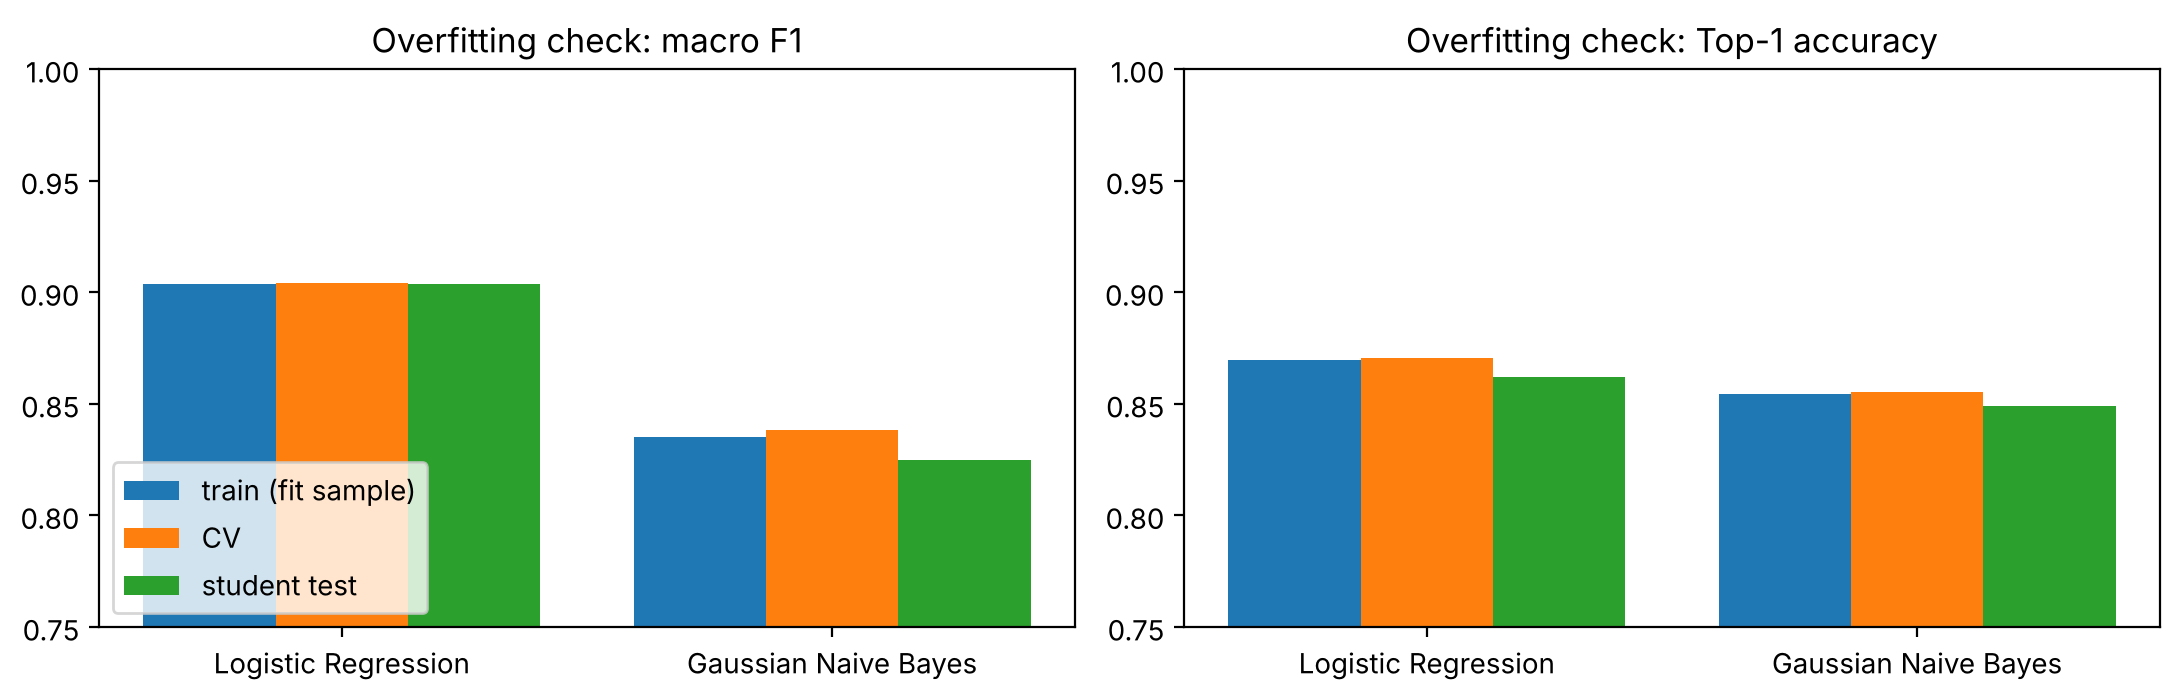

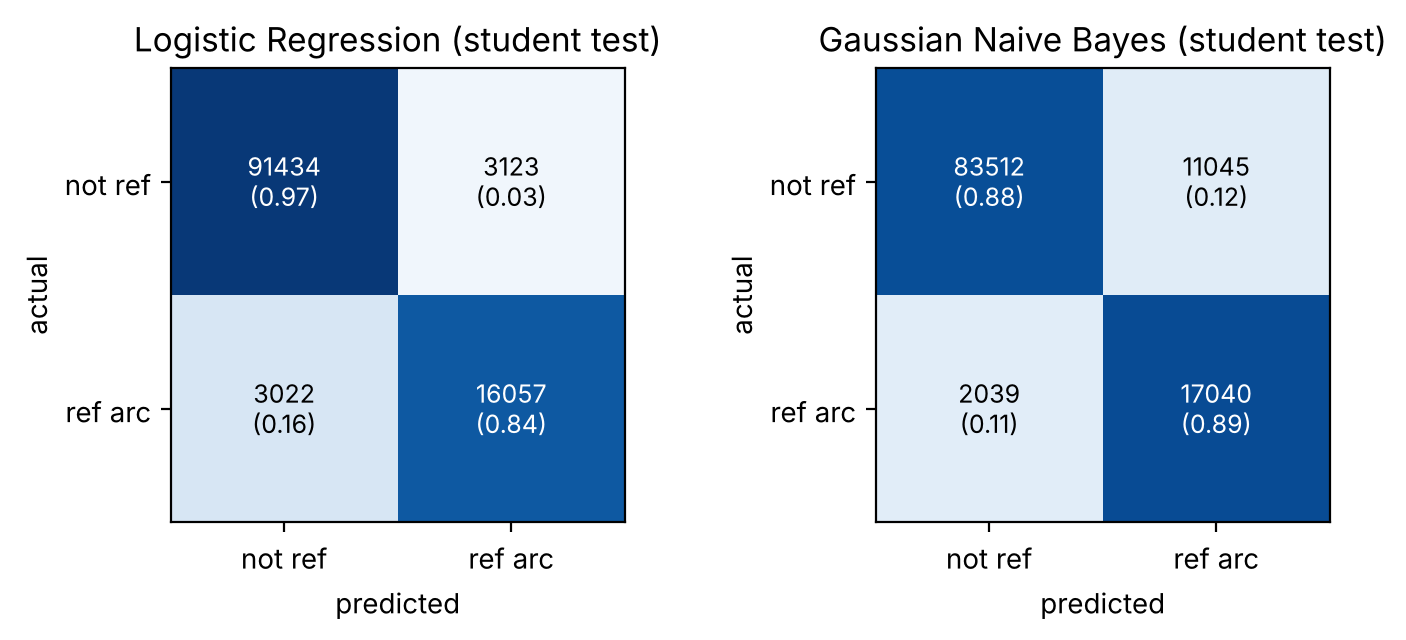

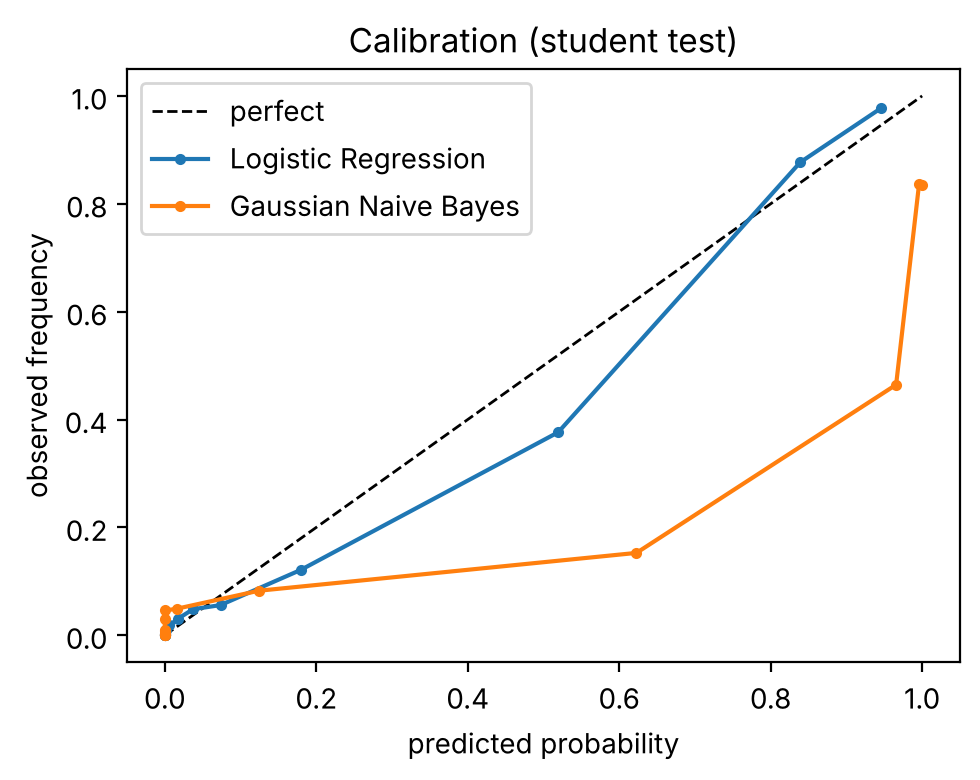

In [11]:
nb.plot_cv_folds({"Logistic Regression": cv_logreg, "Gaussian Naive Bayes": cv_gnb})
nb.plot_overfit({"Logistic Regression": (train_logreg, cv_logreg, test_logreg), "Gaussian Naive Bayes": (train_gnb, cv_gnb, test_gnb)})
nb.plot_confusion({"Logistic Regression": test_logreg["confusion"], "Gaussian Naive Bayes": test_gnb["confusion"]})
nb.plot_calibration(te.label.to_numpy(), {"Logistic Regression": p_logreg, "Gaussian Naive Bayes": p_gnb})

In [12]:
rows = []
for name, cv, t, h in [("Logistic Regression", cv_logreg, test_logreg, hmm_logreg), ("Gaussian Naive Bayes", cv_gnb, test_gnb, hmm_gnb)]:
    rows.append({"model": name, "CV macro F1": cv.macro_f1.mean(), "CV std": cv.macro_f1.std(),
                 "test Top-1": t["top1"], "test macro F1": t["macro_f1"], "test log loss": t["log_loss"],
                 "test continuity": t["continuity"], "Top-1 + HMM (trip mean)": h.hmm_top1.mean(),
                 "route F1 + HMM (trip mean)": h.hmm_route_f1.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV macro F1,CV std,test Top-1,test macro F1,test log loss,test continuity,Top-1 + HMM (trip mean),route F1 + HMM (trip mean)
model,,,,,,,,
Logistic Regression,0.9042,0.0186,0.8621,0.9034,0.1510,0.9188,0.9253,0.9538
Gaussian Naive Bayes,0.8380,0.0200,0.8490,0.8250,0.5074,0.9034,0.9096,0.9263
